# Data exploration with pandas and sklearn

## The goal of this homework is to discover structure in an unlabeled dataset. The observations in this dataset belong to several different clusters. The specific goal is to identify how many clusters there are and to which cluster each point belongs.

## Question 1 (5 points). Load the dataset into a pandas dataframe. Each row represents a single observation; the values in the columns are numeric features recorded for that observation (in other words, this is a 'tidy' dataset). How many rows and columns are there? What is the dimension of this dataset? In other words, how many different features are there for each observation?

In [8]:
# Load the dataset into a pandas DataFrame.
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv('data/dataset.csv')
rows, columns = df.shape
print(f'Rows: {rows}')
print(f'Columns: {columns}')
print(f'Dataset dimension: {df.shape}')
print(f'Features per observation: {columns}')

Rows: 496
Columns: 10
Dataset dimension: (496, 10)
Features per observation: 10


## Question 2 (5 points). Make a scatter plot of `dim1` versus `dim2`, ie the first column versus the second one. How many clusters do you see in this plot?

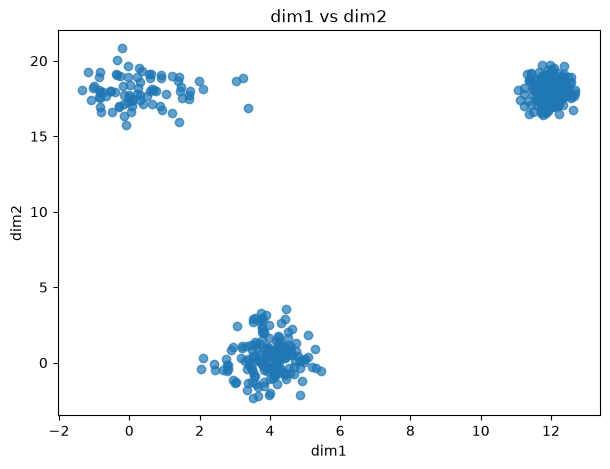

I see 3 clusters in this plot.


In [9]:
plt.figure(figsize=(7, 5))
plt.scatter(df['dim1'], df['dim2'], alpha=0.7)
plt.xlabel('dim1')
plt.ylabel('dim2')
plt.title('dim1 vs dim2')
plt.show()

print('I see 3 clusters in this plot.')

## Question 3 (15 points). Perform principal components analysis (PCA) on the dataset, following along with the example in the lectures10and11 notebook. What fraction of the variation in the dataset is captured by the first two components? Make a plot of the first component against the second component. Now how many clusters do you see in the data? (2 points extra credit if you standardize the data first using `sklearn.preprocessing.StandardScaler`; see the lectures10and11 notebook for an example of how to do that.)

Fraction of variation captured by the first two components: 0.865 (86.5%)


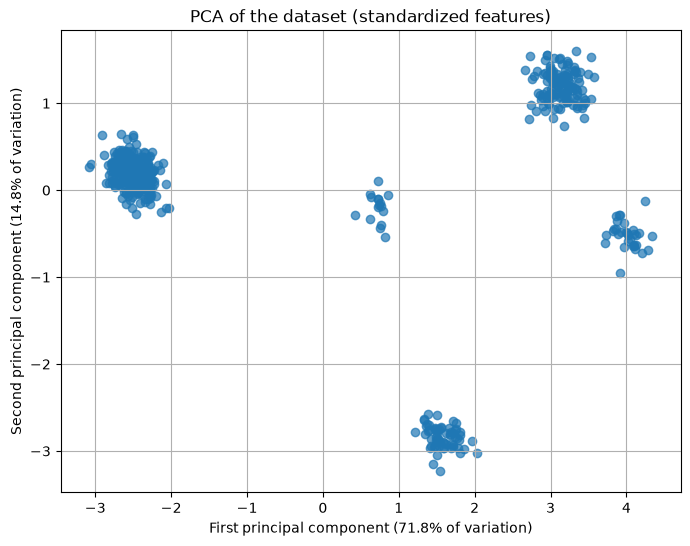

In [10]:
# Import PCA and standardize the features first (extra credit).
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# Fit PCA using the first two components.
pca = PCA(n_components=2)
pca.fit(X_scaled)

# Report the fraction of variation captured by the first two components.
variance_captured = pca.explained_variance_ratio_.sum()
print(f"Fraction of variation captured by the first two components: {variance_captured:.3f} ({variance_captured:.1%})")

# Project the data onto the first two principal components.
X_pca = pca.transform(X_scaled)

# Plot the first component against the second component.
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.7)
plt.xlabel(f"First principal component ({pca.explained_variance_ratio_[0]:.1%} of variation)")
plt.ylabel(f"Second principal component ({pca.explained_variance_ratio_[1]:.1%} of variation)")
plt.title("PCA of the dataset (standardized features)")
plt.grid(True)
plt.show()


## Question 4 (15 points). Use the KMeans clustering algorithm from scikit-learn to assign each point in the dataset to a cluster. Configure KMeans to find a number of clusters equal to the number that you identified visually in the PCA plot from question 3. What are the sizes of the different clusters (how many points are in each cluster)? Remake the PCA scatter plot (PC1 versus PC2) colored by the cluster labels.

cluster sizes: clusters
0    256
1     32
2     64
3    128
4     16
Name: count, dtype: int64


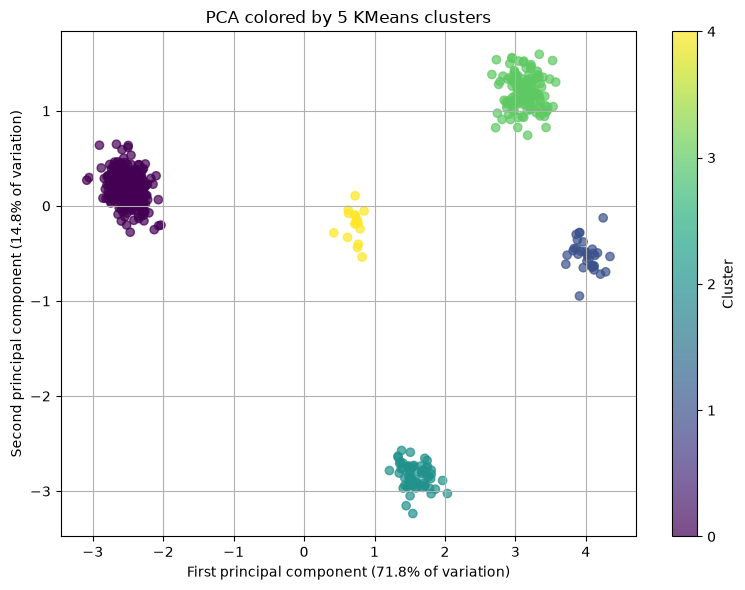

In [11]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# The PCA plot shows five visually distinct groups.
nclust = 5

# Recreate the standardized PCA inputs so this cell does not depend on prior execution state.
X_scaled = StandardScaler().fit_transform(df)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Fit KMeans to the standardized features.
kmeans = KMeans(n_clusters=nclust, random_state=42, n_init=10)
kmeans.fit(X_scaled)

# Assign each observation to a cluster and report the cluster sizes.
clusters = kmeans.predict(X_scaled)
df['clusters'] = clusters
print('cluster sizes:', df['clusters'].value_counts().sort_index())

# Plot the PCA components colored by their KMeans cluster assignments.
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap='viridis', alpha=0.7)
plt.xlabel(f"First principal component ({pca.explained_variance_ratio_[0]:.1%} of variation)")
plt.ylabel(f"Second principal component ({pca.explained_variance_ratio_[1]:.1%} of variation)")
plt.title(f"PCA colored by {nclust} KMeans clusters")
plt.colorbar(scatter, ticks=range(nclust), label='Cluster')
plt.grid(True)
plt.tight_layout()
plt.show()



## Question 5. (10 points) Make a 'scatter matrix' plot showing each column of the original dataset plotted against each of the other 9 columns in a big 10x10 array (like we did for the iris dataset in the lectures10and11 notebook). Notice how the number of apparent clusters in the data varies depends on which pairs of features are being plotted against one another. Color the plots using the kmeans clusters like you did in the previous question.
You could use `pd.plotting.scatter_matrix` or try importing seaborn (`import seaborn as sns`) and use `sns.pairplot`. Or (optional) try both and see which looks nicer. `sns.pairplot` has a `hue` argument that you can use for coloring by passing `hue='clusters'`. See the `pd.plotting.scatter_matrix` and `sns.pairplot` examples in the lectures10and11.ipynb jupyter notebook.

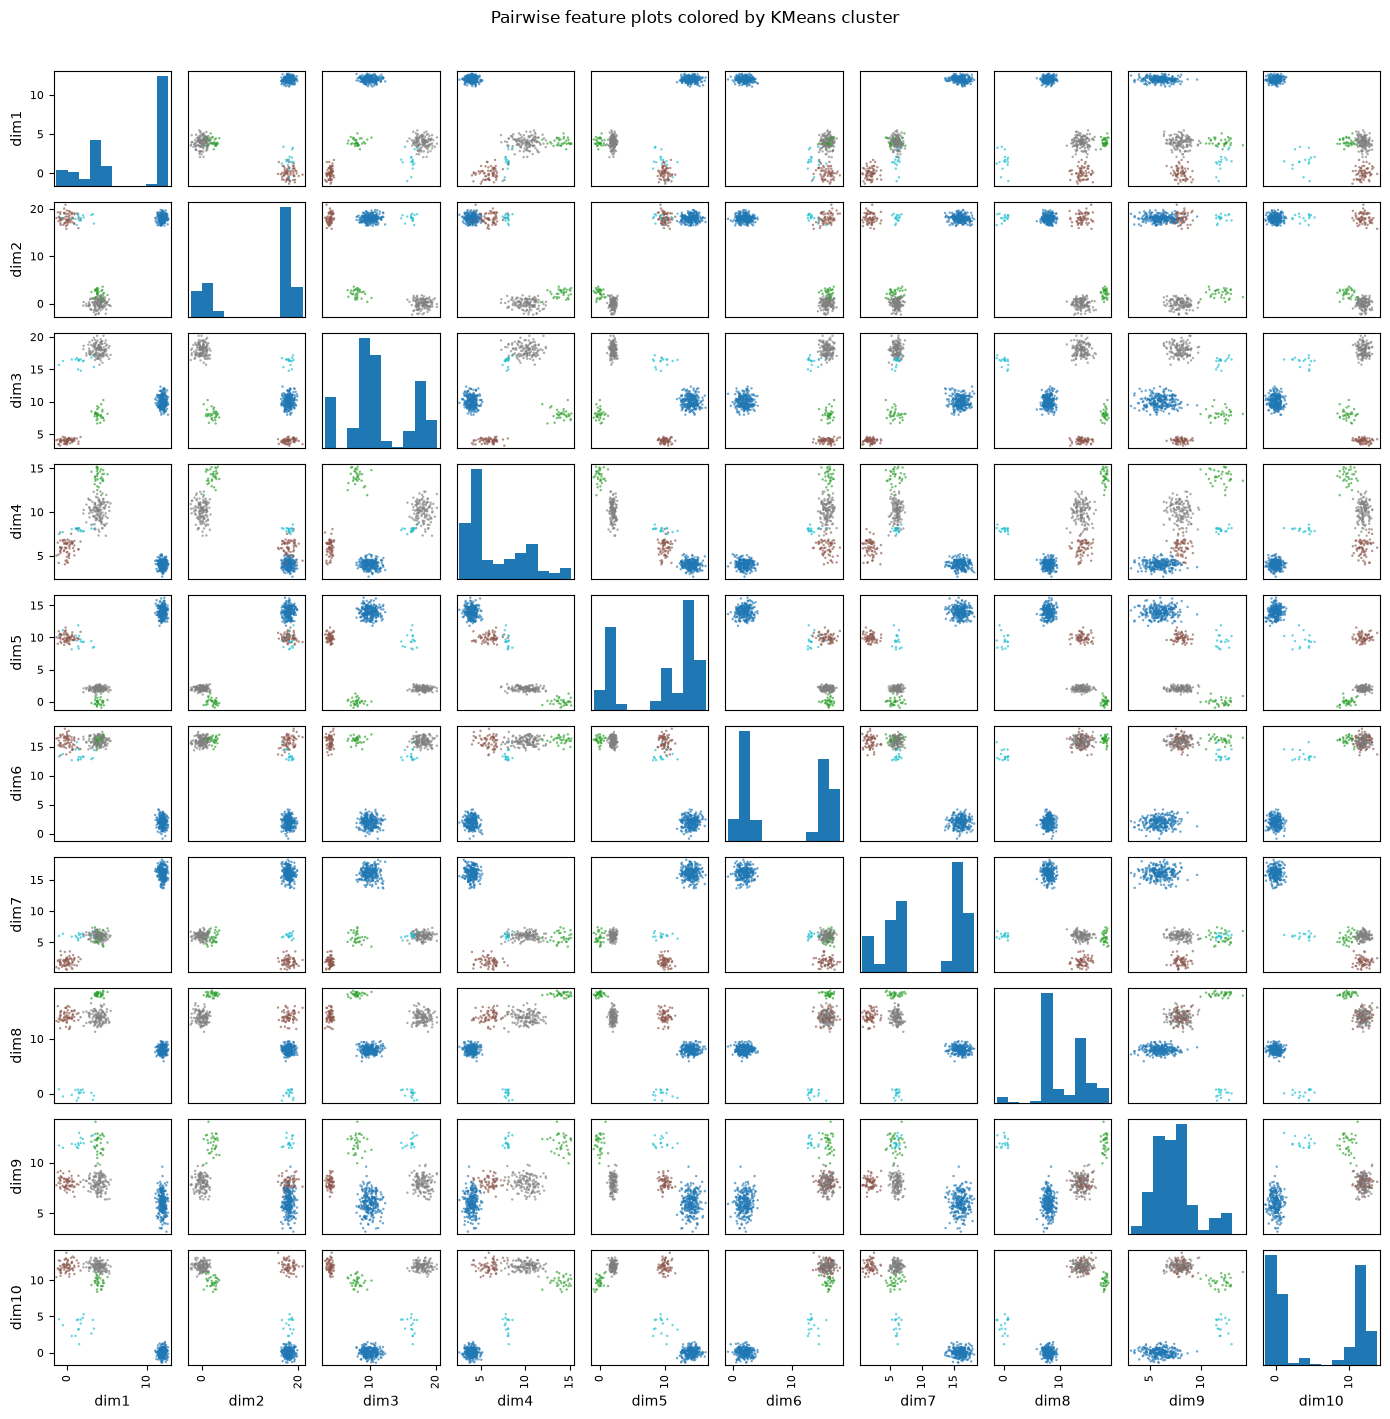

In [12]:
# Plot the original features, using the KMeans labels from Question 4 for color.
feature_data = df.drop(columns='clusters')
axes = pd.plotting.scatter_matrix(
    feature_data,
    c=df['clusters'],
    cmap='tab10',
    alpha=0.65,
    figsize=(14, 14),
    diagonal='hist',
    s=12,
)
fig = axes[0, 0].get_figure()
fig.suptitle('Pairwise feature plots colored by KMeans cluster', y=1.01)
fig.tight_layout()
plt.show()


In [13]:
# and maybe also here if you are trying both and comparing...


## Question 5. (5 points of extra credit) Use the TSNE algorithm in scikit-learn to project the dataset down into 2 dimensions. How many clusters do you see in the TSNE scatter plot?

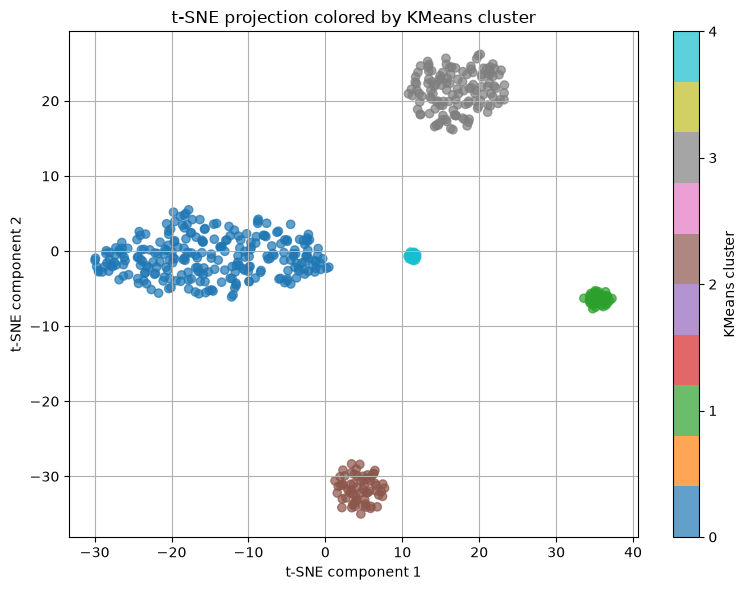

In [14]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# Use the original features, excluding the KMeans labels, and standardize them.
feature_data = df.drop(columns='clusters')
X_scaled = StandardScaler().fit_transform(feature_data)

# Project the data to two dimensions with a reproducible t-SNE fit.
tsne = TSNE(n_components=2, init='pca', learning_rate='auto', random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

# Color each point by its KMeans cluster assignment from Question 4.
cluster_labels = df['clusters'].to_numpy()
cluster_ids = sorted(df['clusters'].unique())
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=cluster_labels, cmap='tab10', alpha=0.7)
plt.xlabel('t-SNE component 1')
plt.ylabel('t-SNE component 2')
plt.title('t-SNE projection colored by KMeans cluster')
plt.colorbar(scatter, ticks=cluster_ids, label='KMeans cluster')
plt.grid(True)
plt.tight_layout()
plt.show()
